# Türkiye'nin Elektrik Dönüşümü
### 2000–2024: Üretim, kaynaklar ve değişen dengeler

**Ders:** Kullanıcı Arayüzü Tasarımı · Veri Hikâyesi / Scrollytelling

**Çalışma sorusu**

> Türkiye'de elektrik üretimi 2000–2024 arasında nasıl değişti; bu dönemde hangi kaynakların üretimi en çok arttı ve fosil yakıtların toplam üretimdeki payı nasıl değişti?

Bu notebook, Ember'ın **Yearly Electricity Data – Europe** CSV dosyasını kullanarak veri kalite kontrollerini, Türkiye filtresini, betimleyici analizi, grafik taslaklarını ve web sitesinde kullanılacak özet dosyaların üretimini kapsar.

**Kapsam:** Türkiye · 2000–2024 · elektrik üretimi (TWh) ve üretim payı (%)

**Veri kaynağı:** [Ember – Yearly Electricity Data](https://ember-energy.org/data/yearly-electricity-data/)

**Lisans:** Kaynak sayfasında belirtilen CC BY 4.0. Yeniden kullanımda Ember'ı ve veri kaynağını belirtin.

> Not: Bu notebook sonuçları hesaplar; sonuçların nedenlerini kendiliğinden kanıtlamaz. Korelasyon veya zaman içindeki birliktelik, tek başına nedensellik anlamına gelmez. Hikâye metnini ve çıkarımları veriler kontrol edildikten sonra kendi ifadelerinizle yazın.

## 1. Ortamı hazırlama

Notebook'u proje kök dizininden veya `notebooks/` klasöründen çalıştırabilirsiniz. Kod, `data/raw/release_generation_yearly_lower.csv` dosyasını bulmak için mevcut dizini ve üst dizinlerini kontrol eder.

Gerekli Python paketleri: `pandas`, `numpy`, `matplotlib`. Notebook Jupyter veya VS Code içindeki Jupyter eklentisiyle çalıştırılabilir.

In [1]:
from pathlib import Path
import json
import shutil

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")

# Analiz ayarları
COUNTRY_NAME = "Türkiye"
COUNTRY_ISO3 = "TUR"
START_YEAR = 2000
END_YEAR = 2024
SOURCE_ACCESS_DATE = "2026-10-16"  # Proje hazırlanırken kaynağın kontrol edildiği tarih
RAW_FILENAME = "release_generation_yearly_lower.csv"

# Notebook'u proje kökünden veya notebooks/ klasöründen açma durumlarını destekle.
possible_roots = [Path.cwd().resolve(), Path.cwd().resolve().parent, Path.cwd().resolve().parent.parent]
PROJECT_ROOT = next(
    (candidate for candidate in possible_roots if (candidate / "data" / "raw" / RAW_FILENAME).exists()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        f"{RAW_FILENAME} bulunamadı. Dosyanın proje içindeki data/raw/ klasöründe olduğundan emin olun. "
        f"Şu anki çalışma dizini: {Path.cwd()}"
    )

RAW_PATH = PROJECT_ROOT / "data" / "raw" / RAW_FILENAME
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
SITE_DATA_DIR = PROJECT_ROOT / "site" / "data"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
SITE_DATA_DIR.mkdir(parents=True, exist_ok=True)

print(f"Proje kökü: {PROJECT_ROOT.name}")
print(f"Ham veri: data/raw/{RAW_FILENAME}")
print(f"Analiz dönemi: {START_YEAR}–{END_YEAR}")

Proje kökü: turkiye-elektrik-donusumu
Ham veri: data/raw/release_generation_yearly_lower.csv
Analiz dönemi: 2000–2024


## 2. Veriyi yükleme ve yapısını tanıma

Önce CSV dosyasının boyutunu, sütunlarını, coğrafi kapsamını ve yıllarını inceliyoruz. Ham dosya değiştirilmeyecek; filtreleme ve türetmeler yeni DataFrame'lerde yapılacak.

In [2]:
raw = pd.read_csv(RAW_PATH, low_memory=False)

print(f"Satır sayısı: {len(raw):,}")
print(f"Sütun sayısı: {raw.shape[1]}")
print(f"Dosya boyutu: {RAW_PATH.stat().st_size / (1024**2):.2f} MB")
display(raw.head())

schema = pd.DataFrame({
    "column": raw.columns,
    "dtype": [str(raw[column].dtype) for column in raw.columns],
    "missing_values": [int(raw[column].isna().sum()) for column in raw.columns],
})
display(schema)

print("\nYıl aralığı:", int(raw["Year"].min()), "–", int(raw["Year"].max()))
print("Coğrafi alan sayısı:", raw["Area"].nunique())
print("Alan türleri:")
display(raw["Area type"].value_counts(dropna=False).rename_axis("Area type").to_frame("rows"))

Satır sayısı: 27,549
Sütun sayısı: 23
Dosya boyutu: 3.90 MB


,Area,ISO 3 code,Year,Area type,Electricity source,Is aggregated source,Generation (TWh),Generation YoY change (TWh),Generation YoY change (%),Share of generation (%),Share of generation YoY change (% points),Emissions (MtCO2e),Emissions YoY change (MtCO2e),Emissions YoY change (%),Share of emissions (%),Emissions intensity (gCO2e/kWh),Continent,Ember region,EU member,OECD member,G20 member,G7 member,ASEAN member
0,Austria,AUT,1990,Country or economy,Solar,False,0.000,NaN,NaN,0.000,NaN,0.000,NaN,NaN,0.000,NaN,Europe,Europe,True,True,False,False,False
1,Austria,AUT,1990,Country or economy,Onshore wind,False,0.000,NaN,NaN,0.000,NaN,0.000,NaN,NaN,0.000,NaN,Europe,Europe,True,True,False,False,False
2,Austria,AUT,1990,Country or economy,Hydro,False,31.510,NaN,NaN,63.954,NaN,0.749,NaN,NaN,6.083,23.770,Europe,Europe,True,True,False,False,False
3,Austria,AUT,1990,Country or economy,Bioenergy,False,1.130,NaN,NaN,2.293,NaN,0.244,NaN,NaN,1.981,215.929,Europe,Europe,True,True,False,False,False
4,Austria,AUT,1990,Country or economy,Other renewables,False,0.000,NaN,NaN,0.000,NaN,0.000,NaN,NaN,0.000,NaN,Europe,Europe,True,True,False,False,False


,column,dtype,missing_values
0,Area,str,0
1,ISO 3 code,str,572
2,Year,int64,0
3,Area type,str,0
4,Electricity source,str,0
5,Is aggregated source,bool,0
6,Generation (TWh),float64,0
7,Generation YoY change (TWh),float64,807
8,Generation YoY change (%),float64,6087
9,Share of generation (%),float64,0



Yıl aralığı: 1985 – 2025
Coğrafi alan sayısı: 38
Alan türleri:


,rows
Area type,
Country or economy,26977
Region,572


### Sütunları yorumlama

- `Area` / `ISO 3 code`: ülke veya bölge.
- `Year`: yıllık gözlem yılı.
- `Electricity source`: üretim kaynağı veya önceden hesaplanmış toplam/kategori.
- `Is aggregated source`: kaydın toplulaştırılmış bir kategori olup olmadığına dair kaynak işareti.
- `Generation (TWh)`: elektrik üretimi, teravatsaat.
- `Share of generation (%)`: ilgili göstergenin üretim içindeki payı.

Aynı yıl için hem kaynak ayrıntıları hem de `Coal`, `Fossil`, `Renewables` ve `Total generation` gibi üst kategoriler bulunduğundan, bütün satırları toplamak **çifte sayım** doğurur. Aşağıda toplam göstergeler ile birbirini dışlayan kaynak seviyeleri ayrı ele alınır.

## 3. Türkiye'yi ve çalışma dönemini seçme

Filtrede ülkenin ISO-3 kodunu ve ülke türünü kullanıyoruz; böylece `EU` gibi bölgesel toplamlar Türkiye verisine karışmıyor.

In [3]:
required_columns = [
    "Area", "ISO 3 code", "Year", "Area type", "Electricity source",
    "Is aggregated source", "Generation (TWh)", "Share of generation (%)"
]
missing_columns = [column for column in required_columns if column not in raw.columns]
if missing_columns:
    raise ValueError(f"CSV'de beklenen sütunlar bulunamadı: {missing_columns}")

country_all_years = raw.loc[
    raw["ISO 3 code"].eq(COUNTRY_ISO3) & raw["Area type"].eq("Country or economy")
].copy()

if country_all_years.empty:
    raise ValueError(f"{COUNTRY_NAME} / {COUNTRY_ISO3} için ülke kaydı bulunamadı.")

analysis = country_all_years.loc[country_all_years["Year"].between(START_YEAR, END_YEAR)].copy()
analysis = analysis.sort_values(["Year", "Electricity source"]).reset_index(drop=True)

print(f"Türkiye için tüm yıllar: {country_all_years['Year'].min()}–{country_all_years['Year'].max()}")
print(f"Seçilen analiz satırları: {len(analysis):,}")
print(f"Seçilen yıl sayısı: {analysis['Year'].nunique()}")
print(f"Seçilen dönemdeki kaynak/kategori sayısı: {analysis['Electricity source'].nunique()}")
display(analysis.head(10)[["Area", "Year", "Electricity source", "Is aggregated source", "Generation (TWh)", "Share of generation (%)"]])

Türkiye için tüm yıllar: 1990–2025
Seçilen analiz satırları: 525
Seçilen yıl sayısı: 25
Seçilen dönemdeki kaynak/kategori sayısı: 21


,Area,Year,Electricity source,Is aggregated source,Generation (TWh),Share of generation (%)
0,Türkiye,2000,Bioenergy,False,0.170,0.137
1,Türkiye,2000,Clean,True,31.160,25.052
2,Türkiye,2000,Coal,True,38.190,30.704
3,Türkiye,2000,Demand,True,127.730,102.693
4,Türkiye,2000,Fossil,True,93.220,74.948
5,Türkiye,2000,Gas,False,46.540,37.418
6,Türkiye,2000,Hard coal,True,3.820,3.071
7,Türkiye,2000,Hydro,False,30.880,24.827
8,Türkiye,2000,"Hydro, bioenergy and other renewables",True,31.130,25.028
9,Türkiye,2000,Lignite,False,34.370,27.633


## 4. Veri kalitesi kontrolleri

Bu bölümde satır tekrarlarını, analiz anahtarındaki tekrarları, seçilen dönemin yıl kapsamasını ve analizde kullanılacak temel alanlardaki eksiklikleri inceliyoruz. Kontroller, veriyi sessizce değiştirmek yerine olası sorunları görünür kılar.

In [4]:
exact_duplicates = int(raw.duplicated().sum())
key_duplicates = int(analysis.duplicated(["Year", "Electricity source"]).sum())
expected_years = list(range(START_YEAR, END_YEAR + 1))
observed_years = sorted(analysis["Year"].unique().tolist())
missing_years = sorted(set(expected_years) - set(observed_years))

required_for_analysis = ["Year", "Electricity source", "Generation (TWh)", "Share of generation (%)"]
missing_by_column = analysis[required_for_analysis].isna().sum().rename("missing_values").to_frame()
rows_per_year = analysis.groupby("Year").size().rename("rows").to_frame()

print(f"Ham dosyadaki birebir tekrarlı satır: {exact_duplicates}")
print(f"Türkiye analizinde Year + Electricity source tekrarı: {key_duplicates}")
print(f"Eksik yıl: {missing_years if missing_years else 'Yok'}")
print("\nAnalizde kullanılan alanlardaki eksik değerler:")
display(missing_by_column)
print("\nYıl başına kayıt sayısı:")
display(rows_per_year.T)

# Bu kontroller beklenen veri yapısı değişirse notebook'un erken hata vermesini sağlar.
assert exact_duplicates == 0, "Ham CSV içinde tekrarlı satırlar bulundu; bunları inceleyin."
assert key_duplicates == 0, "Aynı yıl ve kaynak için birden fazla kayıt bulundu."
assert not missing_years, f"Seçilen dönemde eksik yıl var: {missing_years}"
assert missing_by_column["missing_values"].sum() == 0, "Analizde gereken alanlarda eksik değer var."
assert rows_per_year["rows"].nunique() == 1, "Yıllara göre kaynak kayıt sayıları farklı; nedenini inceleyin."

print("\nKontrol sonucu: temel analiz alanlarında eksik değer, yinelenen yıl-kaynak kaydı veya eksik yıl yok.")

Ham dosyadaki birebir tekrarlı satır: 0
Türkiye analizinde Year + Electricity source tekrarı: 0
Eksik yıl: Yok

Analizde kullanılan alanlardaki eksik değerler:


,missing_values
Year,0
Electricity source,0
Generation (TWh),0
Share of generation (%),0



Yıl başına kayıt sayısı:


Year,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
rows,21,21,21,21,21,21,21,21,21,21,21,21,21,21,21,21,21,21,21,21,21,21,21,21,21



Kontrol sonucu: temel analiz alanlarında eksik değer, yinelenen yıl-kaynak kaydı veya eksik yıl yok.


## 5. Toplam göstergeler ve kaynak hiyerarşisi

Önce Ember'ın sağladığı hazır toplamları (`Total generation`, `Fossil`, `Renewables`, `Coal`) kullanıyoruz. Kaynak kırılımı için ise `Hard coal` ve `Lignite` gibi birbirini dışlayan en alt kaynakları seçiyoruz.

**Önemli karar:** `Coal` toplamı, `Hard coal` ve `Lignite` kayıtlarını kapsar. Bu nedenle aynı grafikte hem `Coal` toplamını hem de iki alt kaynağını toplamayacağız. `Hard coal` kaydı `Is aggregated source=True` olsa da `Coal` toplamının altındaki ayrıntılı bileşen olarak kullanılacak. `Net imports` üretim kaynağı değil, dış ticaret akışıdır; üretim kaynaklarının % payı grafiğine eklenmez.

In [5]:
SUMMARY_SOURCES = ["Total generation", "Fossil", "Renewables", "Coal", "Clean", "Demand"]

# Birbirini dışlayan üretim kaynakları. Bu liste, Toplam üretimle aynı toplamı vermelidir.
LEAF_SOURCES = [
    "Solar", "Onshore wind", "Hydro", "Bioenergy", "Other renewables",
    "Nuclear", "Hard coal", "Lignite", "Gas", "Other fossil"
]

observed_sources = set(analysis["Electricity source"].unique())
missing_summary_sources = sorted(set(SUMMARY_SOURCES) - observed_sources)
missing_leaf_sources = sorted(set(LEAF_SOURCES) - observed_sources)
if missing_summary_sources or missing_leaf_sources:
    raise ValueError(
        f"Beklenen kaynak adları bulunamadı. Toplamlar: {missing_summary_sources}; "
        f"ayrıntılı kaynaklar: {missing_leaf_sources}"
    )

source_flags = (
    analysis.loc[analysis["Electricity source"].isin(LEAF_SOURCES + ["Coal", "Fossil", "Renewables", "Total generation"]),
                 ["Electricity source", "Is aggregated source"]]
    .drop_duplicates()
    .sort_values(["Electricity source", "Is aggregated source"])
)
display(source_flags)

,Electricity source,Is aggregated source
0,Bioenergy,False
2,Coal,True
4,Fossil,True
5,Gas,False
6,Hard coal,True
7,Hydro,False
9,Lignite,False
11,Nuclear,False
12,Onshore wind,False
13,Other fossil,False


## 6. Yıllık göstergeleri hazırlama

Yıllık seriler, kaynak dosyadaki önceden hesaplanmış toplam satırlarından oluşturulur. Değişimler burada yeniden hesaplanır; yüzdesel değişimin başlangıç yılı sıfır değilse hesaplanabilir. Kaynağın yuvarlatılmış değerleriyle küçük farklar oluşabileceğinden yüzde puan değişimini, oranların çıkarılması olarak ayrı yorumlarız.

In [6]:
summary_rows = analysis.loc[analysis["Electricity source"].isin(SUMMARY_SOURCES)].copy()
generation_wide = summary_rows.pivot(index="Year", columns="Electricity source", values="Generation (TWh)")
share_wide = summary_rows.pivot(index="Year", columns="Electricity source", values="Share of generation (%)")

annual = pd.DataFrame(index=sorted(analysis["Year"].unique()))
annual.index.name = "Year"
annual["total_generation_twh"] = generation_wide["Total generation"]
annual["fossil_generation_twh"] = generation_wide["Fossil"]
annual["renewables_generation_twh"] = generation_wide["Renewables"]
annual["coal_generation_twh"] = generation_wide["Coal"]
annual["demand_twh"] = generation_wide["Demand"]
annual["fossil_share_pct"] = share_wide["Fossil"]
annual["renewables_share_pct"] = share_wide["Renewables"]
annual["coal_share_pct"] = share_wide["Coal"]
annual["generation_change_twh"] = annual["total_generation_twh"].diff()
annual["generation_change_pct"] = annual["total_generation_twh"].pct_change() * 100
annual = annual.reset_index()

display(annual.head())
display(annual.tail())

,Year,total_generation_twh,fossil_generation_twh,renewables_generation_twh,coal_generation_twh,demand_twh,fossil_share_pct,renewables_share_pct,coal_share_pct,generation_change_twh,generation_change_pct
0,2000,124.380,93.220,31.160,38.190,127.730,74.948,25.052,30.704,NaN,NaN
1,2001,122.240,97.900,24.340,38.420,126.390,80.088,19.912,31.430,-2.140,-1.721
2,2002,128.460,94.500,33.960,32.150,131.610,73.564,26.436,25.027,6.220,5.088
3,2003,139.540,103.980,35.560,32.250,140.110,74.516,25.484,23.112,11.080,8.625
4,2004,149.750,103.440,46.310,34.450,149.070,69.075,30.925,23.005,10.210,7.317


,Year,total_generation_twh,fossil_generation_twh,renewables_generation_twh,coal_generation_twh,demand_twh,fossil_share_pct,renewables_share_pct,coal_share_pct,generation_change_twh,generation_change_pct
20,2020,302.000,174.670,127.330,106.260,301.410,57.838,42.162,35.185,1.820,0.606
21,2021,327.880,211.810,116.070,104.120,326.030,64.600,35.400,31.756,25.880,8.570
22,2022,320.560,186.210,134.350,113.620,323.290,58.089,41.911,35.444,-7.320,-2.233
23,2023,319.790,185.450,134.340,118.030,323.810,57.991,42.009,36.909,-0.770,-0.240
24,2024,341.230,185.580,155.650,121.320,340.240,54.386,45.614,35.554,21.440,6.704


## 7. Toplam üretim, fosil ve yenilenebilir kaynaklar için tutarlılık kontrolü

Özet satırların toplam üretimle tutarlı olup olmadığını kontrol ediyoruz. Üretim ve yüzde değerleri CSV içinde yuvarlatılmış olduğundan tolerans kullanılır.

In [7]:
# Fosil + yenilenebilir üretimin Toplam üretime eşitliği
summary_total_check = (
    annual["fossil_generation_twh"] + annual["renewables_generation_twh"]
    - annual["total_generation_twh"]
)
print("Fosil + yenilenebilir - toplam üretim farkının en büyük mutlak değeri (TWh):",
      float(summary_total_check.abs().max()))
assert np.allclose(summary_total_check, 0, atol=0.01), "Fosil + yenilenebilir toplamı, toplam üretimle uyuşmuyor."

# Ayrıntılı kaynak listesinin toplam üretimi kapsadığını kontrol et.
leaf_generation_wide = (
    analysis.loc[analysis["Electricity source"].isin(LEAF_SOURCES)]
    .pivot(index="Year", columns="Electricity source", values="Generation (TWh)")
    .reindex(columns=LEAF_SOURCES)
)
leaf_total_check = leaf_generation_wide.sum(axis=1) - generation_wide["Total generation"]
print("Ayrıntılı kaynaklar toplamı - toplam üretim farkının en büyük mutlak değeri (TWh):",
      float(leaf_total_check.abs().max()))
assert np.allclose(leaf_total_check, 0, atol=0.01), "Ayrıntılı kaynaklar toplam üretimi karşılamıyor."

leaf_share_wide = (
    analysis.loc[analysis["Electricity source"].isin(LEAF_SOURCES)]
    .pivot(index="Year", columns="Electricity source", values="Share of generation (%)")
    .reindex(columns=LEAF_SOURCES)
)
leaf_share_check = leaf_share_wide.sum(axis=1)
print("Ayrıntılı kaynak paylarının %100'den en büyük farkı (yüzde puan):",
      float((leaf_share_check - 100).abs().max()))
assert np.allclose(leaf_share_check, 100, atol=0.02), "Ayrıntılı kaynak payları %100'e yakın toplam vermiyor."
print("\nKontroller başarılı. Kaynak hiyerarşisi doğru uygulanmış görünüyor.")

Fosil + yenilenebilir - toplam üretim farkının en büyük mutlak değeri (TWh): 5.684341886080802e-14
Ayrıntılı kaynaklar toplamı - toplam üretim farkının en büyük mutlak değeri (TWh): 5.684341886080802e-14
Ayrıntılı kaynak paylarının %100'den en büyük farkı (yüzde puan): 0.0010000000000047748

Kontroller başarılı. Kaynak hiyerarşisi doğru uygulanmış görünüyor.


## 8. Bulgular: 2000 ve 2024 karşılaştırması

Aşağıdaki metrikler CSV'den otomatik hesaplanır. Üretim miktarındaki artış (`TWh`) ile toplam üretimdeki payın değişimi (`yüzde puan`) farklı kavramlardır; yorumlarda birbirine karıştırılmamalıdır.

In [8]:
start = annual.loc[annual["Year"].eq(START_YEAR)].iloc[0]
end = annual.loc[annual["Year"].eq(END_YEAR)].iloc[0]

summary_comparison = pd.DataFrame([
    {"Gösterge": "Toplam elektrik üretimi", "2000": start["total_generation_twh"], "2024": end["total_generation_twh"],
     "Mutlak değişim": end["total_generation_twh"] - start["total_generation_twh"],
     "2000'e göre değişim (%)": (end["total_generation_twh"] / start["total_generation_twh"] - 1) * 100},
    {"Gösterge": "Fosil yakıt üretimi", "2000": start["fossil_generation_twh"], "2024": end["fossil_generation_twh"],
     "Mutlak değişim": end["fossil_generation_twh"] - start["fossil_generation_twh"],
     "2000'e göre değişim (%)": (end["fossil_generation_twh"] / start["fossil_generation_twh"] - 1) * 100},
    {"Gösterge": "Yenilenebilir üretim", "2000": start["renewables_generation_twh"], "2024": end["renewables_generation_twh"],
     "Mutlak değişim": end["renewables_generation_twh"] - start["renewables_generation_twh"],
     "2000'e göre değişim (%)": (end["renewables_generation_twh"] / start["renewables_generation_twh"] - 1) * 100},
    {"Gösterge": "Kömür üretimi", "2000": start["coal_generation_twh"], "2024": end["coal_generation_twh"],
     "Mutlak değişim": end["coal_generation_twh"] - start["coal_generation_twh"],
     "2000'e göre değişim (%)": (end["coal_generation_twh"] / start["coal_generation_twh"] - 1) * 100},
])

share_comparison = pd.DataFrame([
    {"Gösterge": "Fosil yakıtların üretim payı", "2000 (%)": start["fossil_share_pct"], "2024 (%)": end["fossil_share_pct"],
     "Değişim (yüzde puan)": end["fossil_share_pct"] - start["fossil_share_pct"]},
    {"Gösterge": "Yenilenebilirlerin üretim payı", "2000 (%)": start["renewables_share_pct"], "2024 (%)": end["renewables_share_pct"],
     "Değişim (yüzde puan)": end["renewables_share_pct"] - start["renewables_share_pct"]},
    {"Gösterge": "Kömürün üretim payı", "2000 (%)": start["coal_share_pct"], "2024 (%)": end["coal_share_pct"],
     "Değişim (yüzde puan)": end["coal_share_pct"] - start["coal_share_pct"]},
])

display(summary_comparison.round(2))
display(share_comparison.round(2))

,Gösterge,2000,2024,Mutlak değişim,2000'e göre değişim (%)
0,Toplam elektrik üretimi,124.380,341.230,216.850,174.340
1,Fosil yakıt üretimi,93.220,185.580,92.360,99.080
2,Yenilenebilir üretim,31.160,155.650,124.490,399.520
3,Kömür üretimi,38.190,121.320,83.130,217.670


,Gösterge,2000 (%),2024 (%),Değişim (yüzde puan)
0,Fosil yakıtların üretim payı,74.950,54.390,-20.560
1,Yenilenebilirlerin üretim payı,25.050,45.610,20.560
2,Kömürün üretim payı,30.700,35.550,4.850


## 9. Görsel 1 — Toplam elektrik üretimi zaman içinde nasıl değişti?

Bu çizgi grafik genel zaman eğilimini gösterir. Başlıkta veya metinde yalnızca verinin desteklediği betimleyici sonucu kullanın; grafikten tek başına artışın nedenini çıkarmayın.

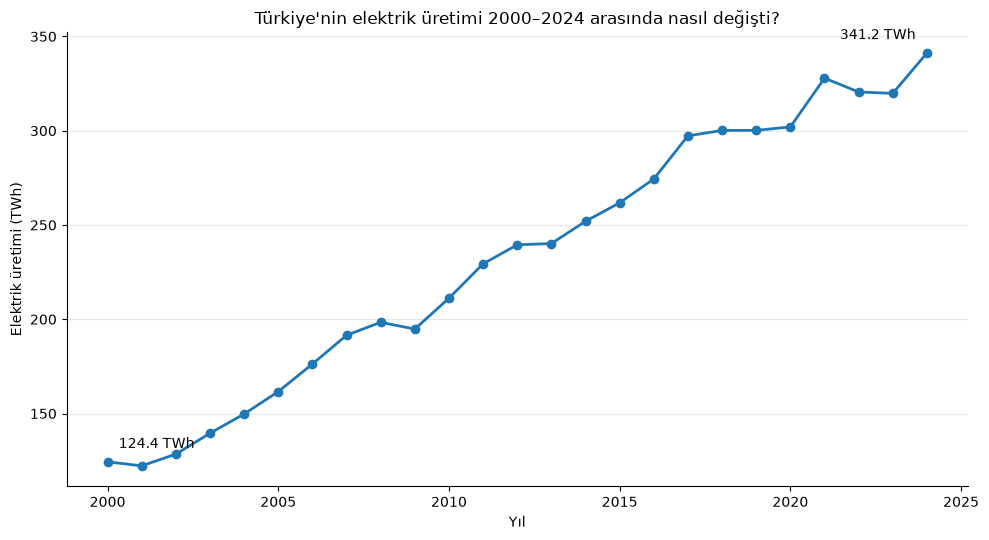

In [9]:
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(annual["Year"], annual["total_generation_twh"], marker="o", linewidth=2)
ax.set_title("Türkiye'nin elektrik üretimi 2000–2024 arasında nasıl değişti?")
ax.set_xlabel("Yıl")
ax.set_ylabel("Elektrik üretimi (TWh)")
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.annotate(
    f"{start['total_generation_twh']:.1f} TWh",
    (START_YEAR, start["total_generation_twh"]),
    xytext=(8, 10), textcoords="offset points"
)
ax.annotate(
    f"{end['total_generation_twh']:.1f} TWh",
    (END_YEAR, end["total_generation_twh"]),
    xytext=(-8, 10), textcoords="offset points", ha="right"
)
plt.tight_layout()
plt.show()

## 10. Görsel 2 — Fosil ve yenilenebilir kaynakların payı

Bu çizgi grafikte yüzde değerleri kullanılır. Değişimi yüzde puanla ifade etmek gerekir: örneğin %60'tan %50'ye düşüş, 10 yüzde puanlık azalıştır.

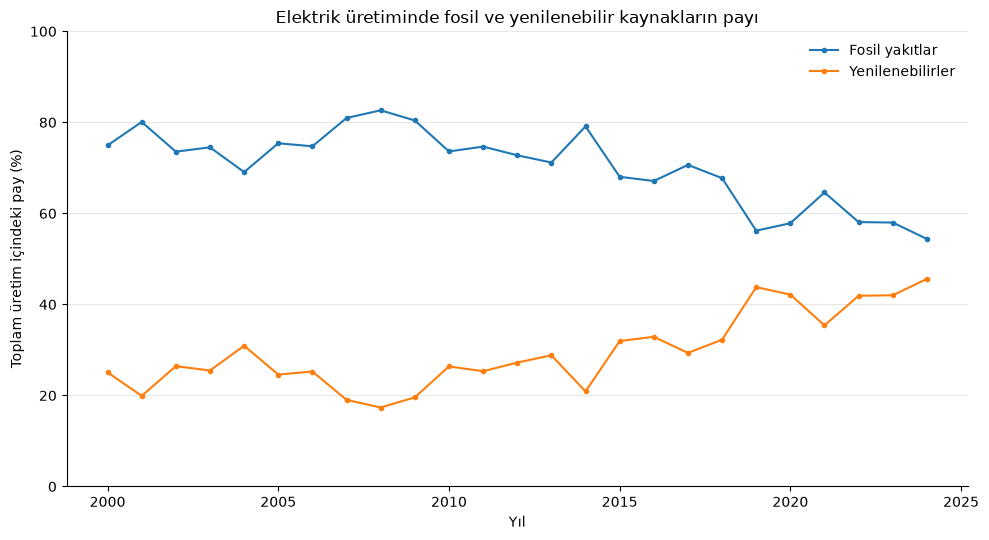

In [10]:
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(annual["Year"], annual["fossil_share_pct"], marker="o", markersize=3, label="Fosil yakıtlar")
ax.plot(annual["Year"], annual["renewables_share_pct"], marker="o", markersize=3, label="Yenilenebilirler")
ax.set_title("Elektrik üretiminde fosil ve yenilenebilir kaynakların payı")
ax.set_xlabel("Yıl")
ax.set_ylabel("Toplam üretim içindeki pay (%)")
ax.set_ylim(0, 100)
ax.grid(axis="y", alpha=0.3)
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## 11. Görsel 3 — Kaynak karmasının zaman içindeki değişimi

Aşağıdaki yığılmış alan grafiği, birbirini dışlayan kaynakların toplam üretim içindeki payını gösterir. `Coal` üst toplamı ayrıca eklenmemiştir; kömürün alt bileşenleri `Hard coal` ve `Lignite` olarak ayrı gösterilir.

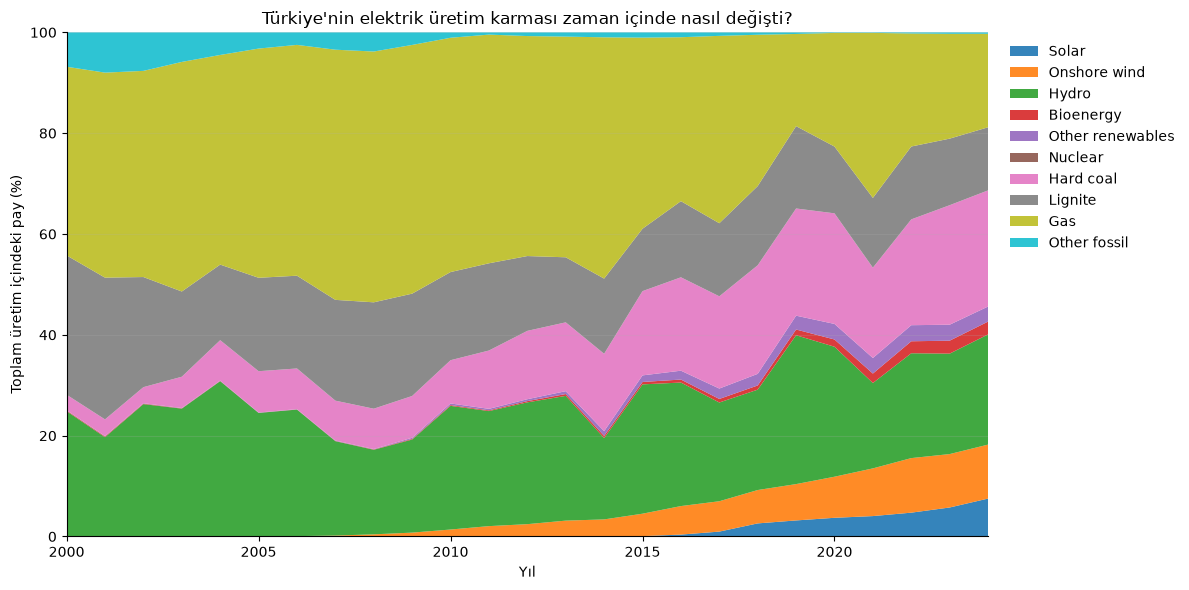

In [11]:
share_plot = leaf_share_wide.sort_index()
fig, ax = plt.subplots(figsize=(12, 6))
ax.stackplot(
    share_plot.index,
    [share_plot[source] for source in LEAF_SOURCES],
    labels=LEAF_SOURCES,
    alpha=0.9,
)
ax.set_title("Türkiye'nin elektrik üretim karması zaman içinde nasıl değişti?")
ax.set_xlabel("Yıl")
ax.set_ylabel("Toplam üretim içindeki pay (%)")
ax.set_ylim(0, 100)
ax.set_xlim(START_YEAR, END_YEAR)
ax.grid(axis="y", alpha=0.2)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## 12. Görsel 4 — Üretim artışına en çok katkıda bulunan kaynaklar

Kaynak bazında mutlak üretim farkını hesaplıyoruz. İlk yıl üretimi sıfır olan bir kaynakta yüzde büyüme tanımsız olabileceği için, karşılaştırmada öncelikle `TWh` cinsinden mutlak farka bakılır.

,source,generation_2000_twh,generation_2024_twh,share_2000_pct,share_2024_pct,absolute_change_twh,share_change_pp,percent_change_from_2000
0,Hard coal,3.820,78.610,3.070,23.040,74.790,19.970,"1,957.850"
1,Hydro,30.880,74.570,24.830,21.850,43.690,-2.970,141.480
2,Onshore wind,0.030,36.530,0.020,10.700,36.500,10.680,"121,666.670"
3,Solar,0.000,25.670,0.000,7.520,25.670,7.520,NaN
4,Gas,46.540,63.280,37.420,18.550,16.740,-18.870,35.970
5,Other renewables,0.080,10.200,0.060,2.990,10.120,2.920,"12,650.000"
6,Bioenergy,0.170,8.680,0.140,2.540,8.510,2.410,"5,005.880"
7,Lignite,34.370,42.710,27.630,12.520,8.340,-15.120,24.270
8,Nuclear,0.000,0.000,0.000,0.000,0.000,0.000,NaN
9,Other fossil,8.490,0.980,6.830,0.290,-7.510,-6.540,-88.460


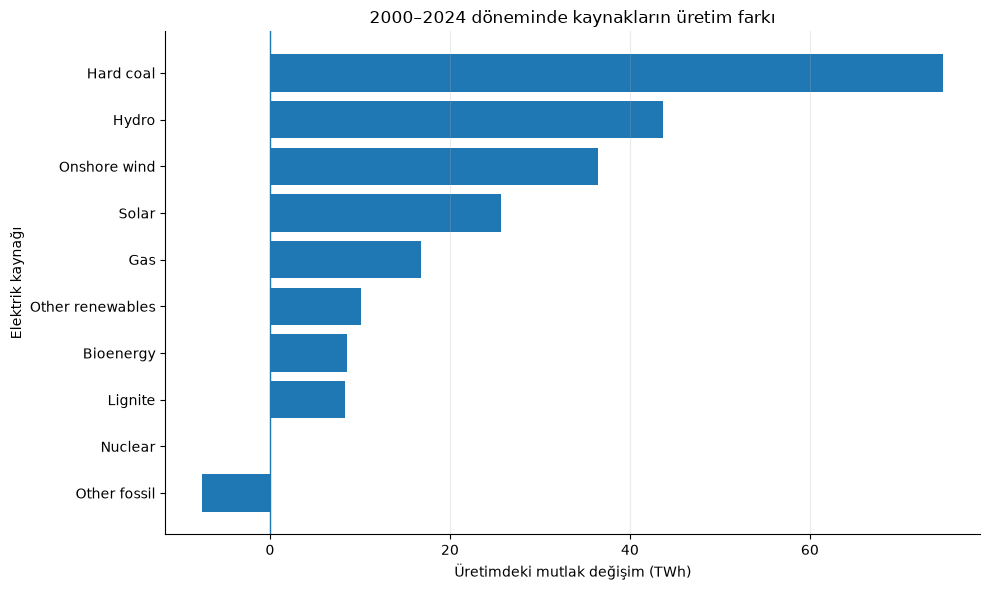

In [12]:
leaf_generation = (
    analysis.loc[analysis["Electricity source"].isin(LEAF_SOURCES)]
    .pivot(index="Year", columns="Electricity source", values="Generation (TWh)")
    .reindex(columns=LEAF_SOURCES)
)
leaf_share = (
    analysis.loc[analysis["Electricity source"].isin(LEAF_SOURCES)]
    .pivot(index="Year", columns="Electricity source", values="Share of generation (%)")
    .reindex(columns=LEAF_SOURCES)
)

source_change = pd.DataFrame({
    "source": LEAF_SOURCES,
    "generation_2000_twh": [leaf_generation.loc[START_YEAR, s] for s in LEAF_SOURCES],
    "generation_2024_twh": [leaf_generation.loc[END_YEAR, s] for s in LEAF_SOURCES],
    "share_2000_pct": [leaf_share.loc[START_YEAR, s] for s in LEAF_SOURCES],
    "share_2024_pct": [leaf_share.loc[END_YEAR, s] for s in LEAF_SOURCES],
})
source_change["absolute_change_twh"] = source_change["generation_2024_twh"] - source_change["generation_2000_twh"]
source_change["share_change_pp"] = source_change["share_2024_pct"] - source_change["share_2000_pct"]
source_change["percent_change_from_2000"] = np.where(
    source_change["generation_2000_twh"].ne(0),
    (source_change["generation_2024_twh"] / source_change["generation_2000_twh"] - 1) * 100,
    np.nan,
)
source_change = source_change.sort_values("absolute_change_twh", ascending=False).reset_index(drop=True)
display(source_change.round(2))

plot_data = source_change.sort_values("absolute_change_twh", ascending=True)
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(plot_data["source"], plot_data["absolute_change_twh"])
ax.set_title(f"{START_YEAR}–{END_YEAR} döneminde kaynakların üretim farkı")
ax.set_xlabel("Üretimdeki mutlak değişim (TWh)")
ax.set_ylabel("Elektrik kaynağı")
ax.axvline(0, linewidth=1)
ax.grid(axis="x", alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## 13. Bulguları kontrol etme ve hikâye için aday noktalar

Bu bölüm bulguları otomatik bir rapor cümlesine dönüştürmek yerine temel ölçümleri toplar. Nihai başlık ve anlatım, notebook çıktıları incelendikten sonra öğrenci tarafından yazılmalıdır.

In [13]:
total_growth_pct = (end["total_generation_twh"] / start["total_generation_twh"] - 1) * 100
fossil_growth_pct = (end["fossil_generation_twh"] / start["fossil_generation_twh"] - 1) * 100
renewables_growth_pct = (end["renewables_generation_twh"] / start["renewables_generation_twh"] - 1) * 100
fossil_share_change_pp = end["fossil_share_pct"] - start["fossil_share_pct"]
renewables_share_change_pp = end["renewables_share_pct"] - start["renewables_share_pct"]
top_source = source_change.iloc[0]

print(f"Toplam üretim: {start['total_generation_twh']:.2f} → {end['total_generation_twh']:.2f} TWh ({total_growth_pct:+.1f}%).")
print(f"Fosil yakıt üretimi: {start['fossil_generation_twh']:.2f} → {end['fossil_generation_twh']:.2f} TWh ({fossil_growth_pct:+.1f}%).")
print(f"Yenilenebilir üretim: {start['renewables_generation_twh']:.2f} → {end['renewables_generation_twh']:.2f} TWh ({renewables_growth_pct:+.1f}%).")
print(f"Fosil yakıtların üretim payı değişimi: {fossil_share_change_pp:+.2f} yüzde puan.")
print(f"Yenilenebilirlerin üretim payı değişimi: {renewables_share_change_pp:+.2f} yüzde puan.")
print(f"En fazla mutlak üretim artışı olan kaynak: {top_source['source']} ({top_source['absolute_change_twh']:+.2f} TWh).")

print("\nStoryboard hazırlarken cevaplanacak sorular:")
print("1. Toplam üretim hangi dönemlerde daha hızlı veya daha yavaş değişmiş?")
print("2. Yenilenebilir payındaki değişime hangi kaynaklar katkıda bulunmuş?")
print("3. Fosil üretim miktarı ile fosil payı aynı yönde mi değişmiş?")
print("4. Hangi tek bulgu açılış başlığı için en güçlü ve en dürüst seçenek?")

Toplam üretim: 124.38 → 341.23 TWh (+174.3%).
Fosil yakıt üretimi: 93.22 → 185.58 TWh (+99.1%).
Yenilenebilir üretim: 31.16 → 155.65 TWh (+399.5%).
Fosil yakıtların üretim payı değişimi: -20.56 yüzde puan.
Yenilenebilirlerin üretim payı değişimi: +20.56 yüzde puan.
En fazla mutlak üretim artışı olan kaynak: Hard coal (+74.79 TWh).

Storyboard hazırlarken cevaplanacak sorular:
1. Toplam üretim hangi dönemlerde daha hızlı veya daha yavaş değişmiş?
2. Yenilenebilir payındaki değişime hangi kaynaklar katkıda bulunmuş?
3. Fosil üretim miktarı ile fosil payı aynı yönde mi değişmiş?
4. Hangi tek bulgu açılış başlığı için en güçlü ve en dürüst seçenek?


## 14. Web sitesinde kullanılacak özet verileri dışa aktarma

Ham CSV web sayfasına taşınmayacak. Aşağıdaki dosyalar hem `data/processed/` hem de web tarafında kullanılmak üzere `site/data/` içine kaydedilir.

- `annual_metrics.csv`: yıllık toplam üretim, fosil/yenilenebilir/ kömür üretimi ve payları.
- `generation_mix.csv`: kaynak bazında yıl, üretim ve pay (uzun format).
- `source_change_2000_2024.csv`: kaynakların başlangıç-bitiş karşılaştırması.
- `story_metrics.json`: web sayfasında kullanılabilecek özet metrikler ve kaynak metaverisi.

In [14]:
annual_export = annual.copy()
annual_export.to_csv(PROCESSED_DIR / "annual_metrics.csv", index=False, encoding="utf-8")

mix_export = (
    analysis.loc[analysis["Electricity source"].isin(LEAF_SOURCES),
                 ["Year", "Electricity source", "Generation (TWh)", "Share of generation (%)"]]
    .rename(columns={
        "Electricity source": "source",
        "Generation (TWh)": "generation_twh",
        "Share of generation (%)": "share_pct",
    })
    .sort_values(["Year", "source"])
    .reset_index(drop=True)
)
mix_export.to_csv(PROCESSED_DIR / "generation_mix.csv", index=False, encoding="utf-8")

source_change_export = source_change.copy()
source_change_export.to_csv(PROCESSED_DIR / "source_change_2000_2024.csv", index=False, encoding="utf-8")

story_metrics = {
    "project_title": "Türkiye'nin Elektrik Dönüşümü",
    "subtitle": "2000–2024: Üretim, kaynaklar ve değişen dengeler",
    "research_question": "Türkiye'de elektrik üretimi 2000–2024 arasında nasıl değişti; bu dönemde hangi kaynakların üretimi en çok arttı ve fosil yakıtların toplam üretimdeki payı nasıl değişti?",
    "country": COUNTRY_NAME,
    "country_iso3": COUNTRY_ISO3,
    "start_year": START_YEAR,
    "end_year": END_YEAR,
    "source_name": "Ember – Yearly Electricity Data (Europe CSV)",
    "source_url": "https://ember-energy.org/data/yearly-electricity-data/",
    "license": "CC BY 4.0 (kaynak sayfasında belirtildiği üzere)",
    "source_access_date": SOURCE_ACCESS_DATE,
    "units": {"generation": "TWh", "share": "%", "share_change": "percentage points"},
    "metrics": {
        "total_generation_start_twh": round(float(start["total_generation_twh"]), 3),
        "total_generation_end_twh": round(float(end["total_generation_twh"]), 3),
        "total_generation_change_pct": round(float(total_growth_pct), 3),
        "fossil_generation_start_twh": round(float(start["fossil_generation_twh"]), 3),
        "fossil_generation_end_twh": round(float(end["fossil_generation_twh"]), 3),
        "fossil_generation_change_pct": round(float(fossil_growth_pct), 3),
        "renewables_generation_start_twh": round(float(start["renewables_generation_twh"]), 3),
        "renewables_generation_end_twh": round(float(end["renewables_generation_twh"]), 3),
        "renewables_generation_change_pct": round(float(renewables_growth_pct), 3),
        "fossil_share_start_pct": round(float(start["fossil_share_pct"]), 3),
        "fossil_share_end_pct": round(float(end["fossil_share_pct"]), 3),
        "fossil_share_change_pp": round(float(fossil_share_change_pp), 3),
        "renewables_share_start_pct": round(float(start["renewables_share_pct"]), 3),
        "renewables_share_end_pct": round(float(end["renewables_share_pct"]), 3),
        "renewables_share_change_pp": round(float(renewables_share_change_pp), 3),
        "largest_absolute_source_increase": str(top_source["source"]),
        "largest_absolute_source_increase_twh": round(float(top_source["absolute_change_twh"]), 3),
    },
    "method_notes": [
        "Toplam göstergelerde Ember'ın sağladığı toplulaştırılmış satırlar kullanılmıştır.",
        "Kaynak kırılımında çifte sayımı önlemek için birbirini dışlayan kaynak bileşenleri kullanılmıştır.",
        "Net imports bir elektrik üretim kaynağı olmadığı için üretim karması yüzdelerine dahil edilmemiştir.",
        "Bu analiz betimleyicidir; zaman içindeki değişimler tek başına nedensellik göstermez."
    ],
}
json_path = PROCESSED_DIR / "story_metrics.json"
json_path.write_text(json.dumps(story_metrics, ensure_ascii=False, indent=2), encoding="utf-8")

# Web sayfası aynı üretilmiş verileri okur; ham veri kopyalanmaz.
for filename in ["annual_metrics.csv", "generation_mix.csv", "source_change_2000_2024.csv", "story_metrics.json"]:
    shutil.copy2(PROCESSED_DIR / filename, SITE_DATA_DIR / filename)

print("Dışa aktarılan dosyalar:")
for path in sorted(PROCESSED_DIR.glob("*")):
    if path.is_file():
        print(f"- {path.relative_to(PROJECT_ROOT)} ({path.stat().st_size:,} byte)")
print("\nSite veri dizini:", SITE_DATA_DIR.relative_to(PROJECT_ROOT))

Dışa aktarılan dosyalar:
- data/processed/annual_metrics.csv (2,573 byte)
- data/processed/generation_mix.csv (6,471 byte)
- data/processed/source_change_2000_2024.csv (807 byte)
- data/processed/story_metrics.json (2,009 byte)

Site veri dizini: site/data


## 15. Son kontrol ve yöntem notları

Bu son hücre, dışa aktarılan dosyaların okunabildiğini doğrular. Teslim öncesinde Jupyter'de **Restart Kernel and Run All Cells** (veya eşdeğeri) ile notebook'un tamamını baştan sona tekrar çalıştırın.

### Yöntem ve sınırlılıklar

- Analiz yalnızca Türkiye'nin 2000–2024 yıllarına ait elektrik üretim göstergelerini betimler.
- `Total generation`, `Fossil`, `Renewables` ve `Coal` gibi toplamlar doğrudan toplulaştırılmış kaynak kayıtlarından alınır; birbirine eklenmez.
- Kaynak grafiğinde `Hard coal` ile `Lignite`, `Coal` toplamının bileşenleri olduğu için `Coal` satırı ayrıca kullanılmaz.
- Net ithalat/ithalat-net akışı kaynak kırılımına eklenmez; aksi halde elektrik üretimi ile talep/akış kavramları karışır.
- Üretim miktarı (TWh) ile üretim payı (%) farklı ölçülerdir. Pay değişimi yüzde puanla ifade edilir.
- Bu veriler üretimde **ne değiştiğini** gösterir; politikanın, fiyatların veya başka bir etkenin değişime **neden olduğunu** tek başına kanıtlamaz.
- Veri kaynağı ve lisans bilgisi web sayfasında ve README'de belirtilmelidir.

### Yapay zekâ kullanım beyanı

Bu notebook'un ilk yapısının oluşturulmasında OpenAI ChatGPT'den kod ve çalışma akışı desteği alınmıştır.